# Heart Disease Prediction Using Machine Learning Algorithms

**Dataset:** UCI Heart Disease (repository ID 45)  
**Task:** Binary classification — distinguish records with no diagnosed heart disease from records with heart disease.

This notebook includes exploratory data analysis, leakage-safe preprocessing, cross-validation, eight model options, and a multi-metric evaluation. It is an educational machine-learning exercise, not a clinical diagnostic system.

## 1. Install the dataset package

Run this cell once in your notebook environment. If the package is already installed, pip will report that it is satisfied.

In [45]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [46]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 3. Fetch and prepare the UCI Heart Disease dataset

This uses the UCI repository version (`id=45`). Its original target is commonly encoded from 0 to 4: 0 means no disease and values 1–4 indicate presence of disease. We convert it to a binary target (0/1).

The original Cleveland dataset includes some missing values. Predictor columns are converted to numeric values, and unparseable values become `NaN`; these will be imputed within model pipelines later.

In [47]:
from ucimlrepo import fetch_ucirepo

# Fetch dataset from the UCI Machine Learning Repository
heart_disease = fetch_ucirepo(id=45)

# Separate predictors and original target
X = heart_disease.data.features.copy()
y_original = heart_disease.data.targets.iloc[:, 0].copy()

# Convert predictors to numeric; values such as '?' become missing values
X = X.apply(pd.to_numeric, errors="coerce")

# Convert original target to binary: 0 = no disease, 1 = disease present
y_original = pd.to_numeric(y_original, errors="coerce")
if y_original.isna().any():
    raise ValueError("The UCI target contains missing or non-numeric values.")

y = (y_original > 0).astype(int)

# Build one dataframe for EDA and the modelling workflow
dataset = X.copy()
dataset["target"] = y

print("Dataset shape:", dataset.shape)
print("\\nTarget counts:")
display(dataset["target"].value_counts().sort_index().to_frame("count"))
print("\\nDataset preview:")
display(dataset.head())

print("\\nUCI dataset metadata:")
print(heart_disease.metadata)

Dataset shape: (303, 14)
\nTarget counts:


,count
target,
0,164
1,139


\nDataset preview:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


\nUCI dataset metadata:
{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. 

## 4. Understand the dataset

In [48]:
print("Data types and non-null counts:")
dataset.info()

print("\\nSummary statistics:")
display(dataset.describe().T)

print("\\nMissing values per column:")
display(dataset.isna().sum().to_frame("missing values"))

print("\\nDuplicate rows:", dataset.duplicated().sum())

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB
\nSummary statistics:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


\nMissing values per column:


,missing values
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


\nDuplicate rows: 0


### Feature guide

The UCI Cleveland dataset contains 13 predictors. Some fields are encoded categories; their numeric values should be treated as category codes rather than continuous measurements when interpreting plots.

- `age`: age in years
- `sex`: sex code (1 = male, 0 = female)
- `cp`: chest-pain type code
- `trestbps`: resting blood pressure
- `chol`: serum cholesterol
- `fbs`: fasting blood sugar indicator
- `restecg`: resting electrocardiographic result code
- `thalach`: maximum heart rate achieved
- `exang`: exercise-induced angina indicator
- `oldpeak`: ST depression induced by exercise relative to rest
- `slope`: slope of the peak exercise ST segment code
- `ca`: number of major vessels colored by fluoroscopy (may contain missing values)
- `thal`: thalassemia-related category code (may contain missing values)

**Encoding caution:** the UCI repository's raw `cp` values are generally 1–4, unlike some processed Kaggle files that recode them as 0–3. Always check the actual unique values and repository variable descriptions before attaching category labels.

## 5. Analyse the target variable

Target values: [np.int64(0), np.int64(1)]


,count
target,
0,164
1,139


,percentage
target,
0,54.13
1,45.87


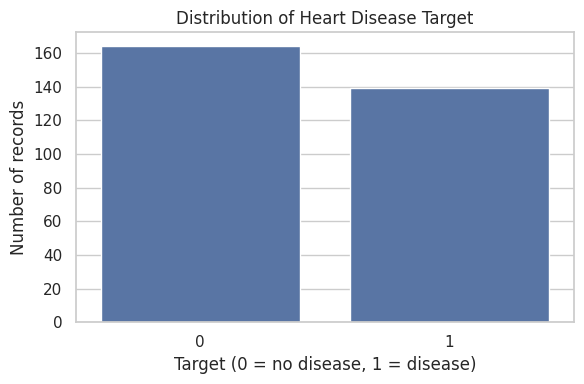

In [49]:
print("Target values:", sorted(dataset["target"].unique()))
target_counts = dataset["target"].value_counts().sort_index()
display(target_counts.to_frame("count"))

target_percent = (dataset["target"].value_counts(normalize=True).sort_index() * 100)
display(target_percent.round(2).to_frame("percentage"))

plt.figure(figsize=(6, 4))
sns.countplot(data=dataset, x="target")
plt.title("Distribution of Heart Disease Target")
plt.xlabel("Target (0 = no disease, 1 = disease)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

## 6. Correlation analysis

Correlation is a descriptive, univariate association. It does not establish causation and is not the same as feature importance for every machine-learning model. Correlations for encoded categorical variables also need careful interpretation.

,absolute correlation
thal,0.525689
ca,0.460442
exang,0.431894
oldpeak,0.424510
thalach,0.417167
cp,0.414446
slope,0.339213
sex,0.276816
age,0.223120
restecg,0.169202


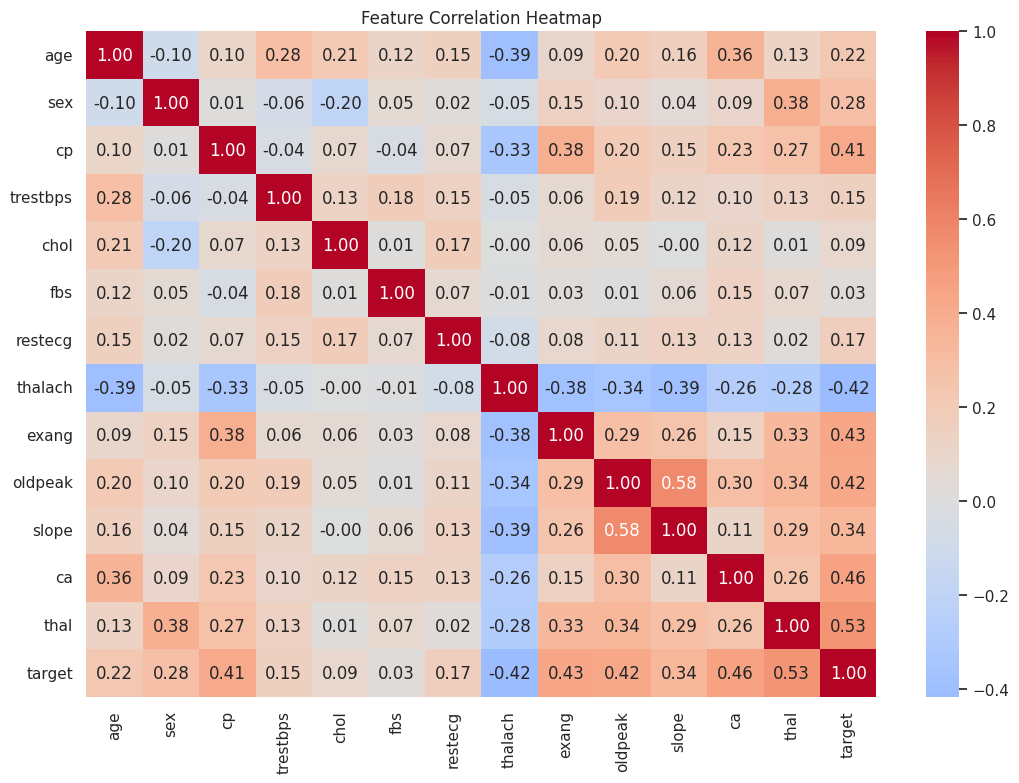

In [50]:
correlations = dataset.corr(numeric_only=True)["target"].drop("target")
display(correlations.abs().sort_values(ascending=False).to_frame("absolute correlation"))

plt.figure(figsize=(11, 8))
sns.heatmap(dataset.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

## 7. Exploratory data analysis

The following plots use explicit keyword arguments (`data=`, `x=`, `y=`), which avoids the positional-argument error from older plotting code. The bar plots show the average binary target within each category, i.e. the observed proportion with target 1.

Sex codes: [np.int64(0), np.int64(1)]


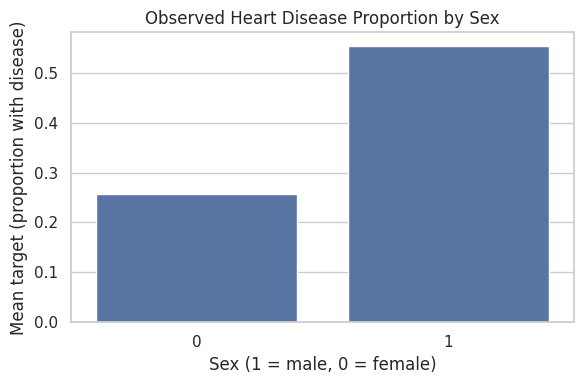

In [51]:
# Sex: 1 = male, 0 = female
print("Sex codes:", sorted(dataset["sex"].dropna().unique()))
plt.figure(figsize=(6, 4))
sns.barplot(data=dataset, x="sex", y="target", ci=None)
plt.title("Observed Heart Disease Proportion by Sex")
plt.xlabel("Sex (1 = male, 0 = female)")
plt.ylabel("Mean target (proportion with disease)")
plt.tight_layout()
plt.show()

Chest pain codes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


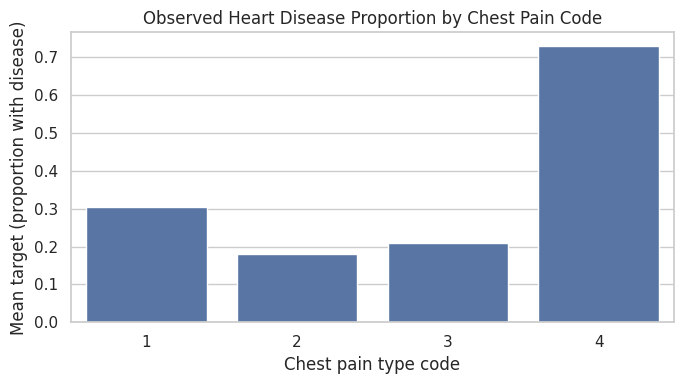

In [52]:
# Chest pain type — preserve UCI's original codes; consult metadata for labels
print("Chest pain codes:", sorted(dataset["cp"].dropna().unique()))
plt.figure(figsize=(7, 4))
sns.barplot(data=dataset, x="cp", y="target", ci=None)
plt.title("Observed Heart Disease Proportion by Chest Pain Code")
plt.xlabel("Chest pain type code")
plt.ylabel("Mean target (proportion with disease)")
plt.tight_layout()
plt.show()

FBS codes: [np.int64(0), np.int64(1)]


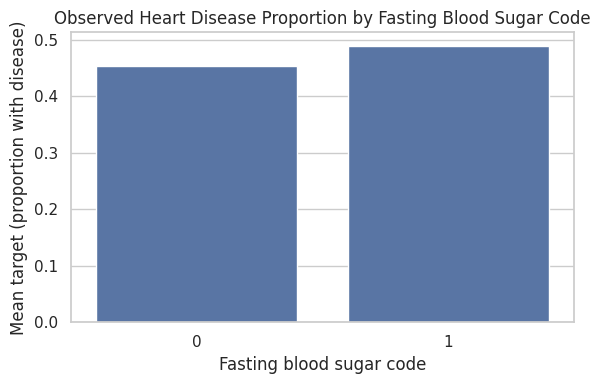

In [53]:
# Fasting blood sugar
print("FBS codes:", sorted(dataset["fbs"].dropna().unique()))
plt.figure(figsize=(6, 4))
sns.barplot(data=dataset, x="fbs", y="target", ci=None)
plt.title("Observed Heart Disease Proportion by Fasting Blood Sugar Code")
plt.xlabel("Fasting blood sugar code")
plt.ylabel("Mean target (proportion with disease)")
plt.tight_layout()
plt.show()

Resting ECG codes: [np.int64(0), np.int64(1), np.int64(2)]


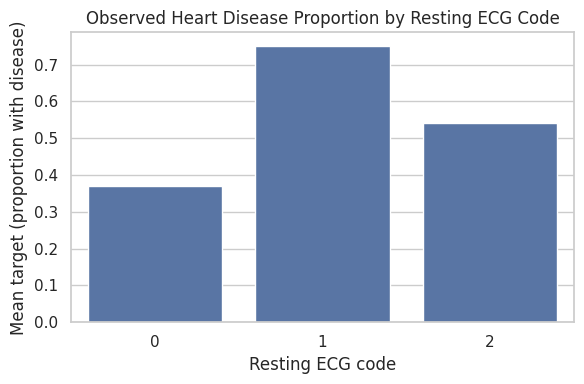

In [54]:
# Resting ECG
print("Resting ECG codes:", sorted(dataset["restecg"].dropna().unique()))
plt.figure(figsize=(6, 4))
sns.barplot(data=dataset, x="restecg", y="target", ci=None)
plt.title("Observed Heart Disease Proportion by Resting ECG Code")
plt.xlabel("Resting ECG code")
plt.ylabel("Mean target (proportion with disease)")
plt.tight_layout()
plt.show()

Exercise-induced angina codes: [np.int64(0), np.int64(1)]


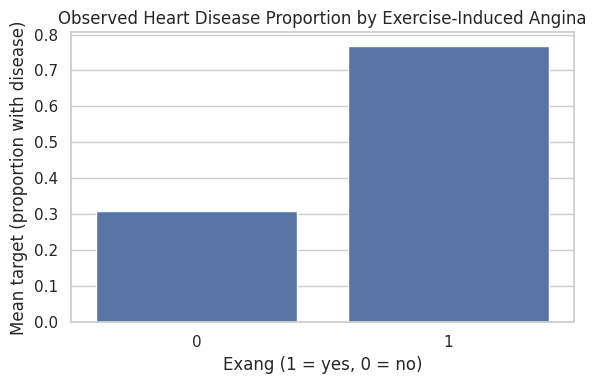

In [55]:
# Exercise-induced angina: 1 = yes, 0 = no
print("Exercise-induced angina codes:", sorted(dataset["exang"].dropna().unique()))
plt.figure(figsize=(6, 4))
sns.barplot(data=dataset, x="exang", y="target", ci=None)
plt.title("Observed Heart Disease Proportion by Exercise-Induced Angina")
plt.xlabel("Exang (1 = yes, 0 = no)")
plt.ylabel("Mean target (proportion with disease)")
plt.tight_layout()
plt.show()

Slope codes: [np.int64(1), np.int64(2), np.int64(3)]


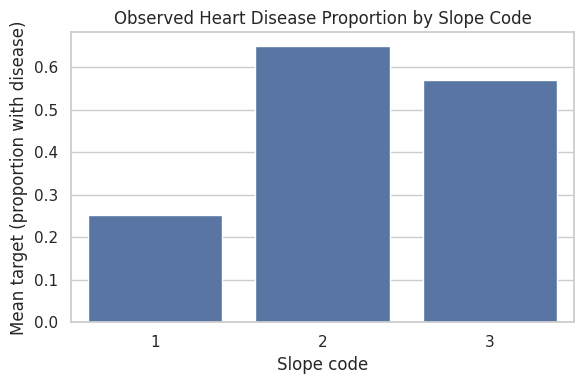

In [56]:
# Slope of peak exercise ST segment
print("Slope codes:", sorted(dataset["slope"].dropna().unique()))
plt.figure(figsize=(6, 4))
sns.barplot(data=dataset, x="slope", y="target", ci=None)
plt.title("Observed Heart Disease Proportion by Slope Code")
plt.xlabel("Slope code")
plt.ylabel("Mean target (proportion with disease)")
plt.tight_layout()
plt.show()

CA values: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]


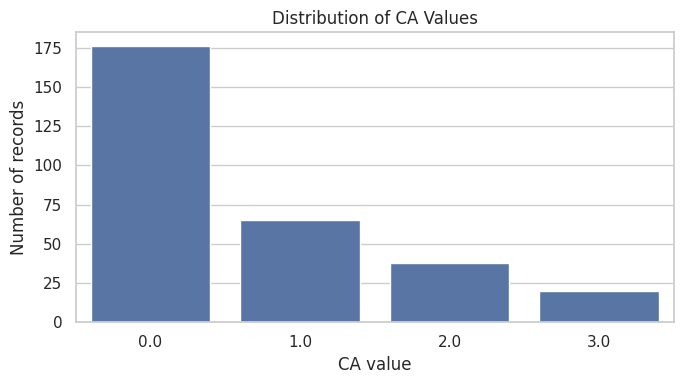

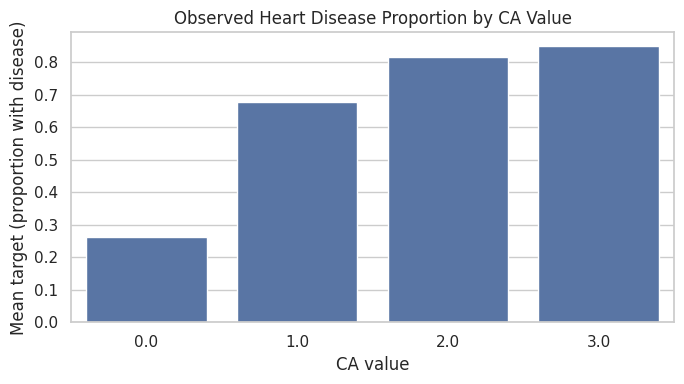

In [57]:
# Number of major vessels colored by fluoroscopy
print("CA values:", sorted(dataset["ca"].dropna().unique()))
plt.figure(figsize=(7, 4))
sns.countplot(data=dataset, x="ca")
plt.title("Distribution of CA Values")
plt.xlabel("CA value")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.barplot(data=dataset, x="ca", y="target", ci=None)
plt.title("Observed Heart Disease Proportion by CA Value")
plt.xlabel("CA value")
plt.ylabel("Mean target (proportion with disease)")
plt.tight_layout()
plt.show()

Thal values: [np.float64(3.0), np.float64(6.0), np.float64(7.0)]


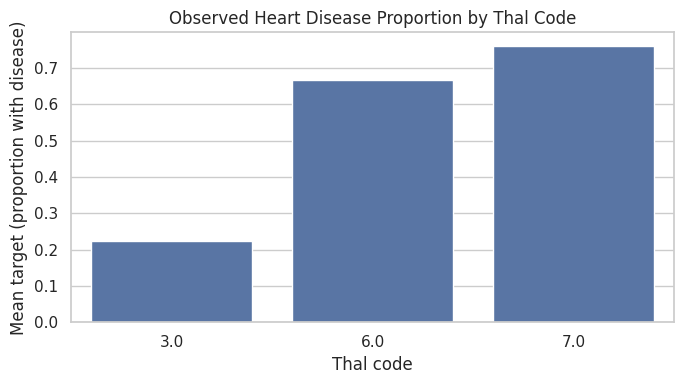

In [58]:
# Thal category code
print("Thal values:", sorted(dataset["thal"].dropna().unique()))
plt.figure(figsize=(7, 4))
sns.barplot(data=dataset, x="thal", y="target", ci=None)
plt.title("Observed Heart Disease Proportion by Thal Code")
plt.xlabel("Thal code")
plt.ylabel("Mean target (proportion with disease)")
plt.tight_layout()
plt.show()

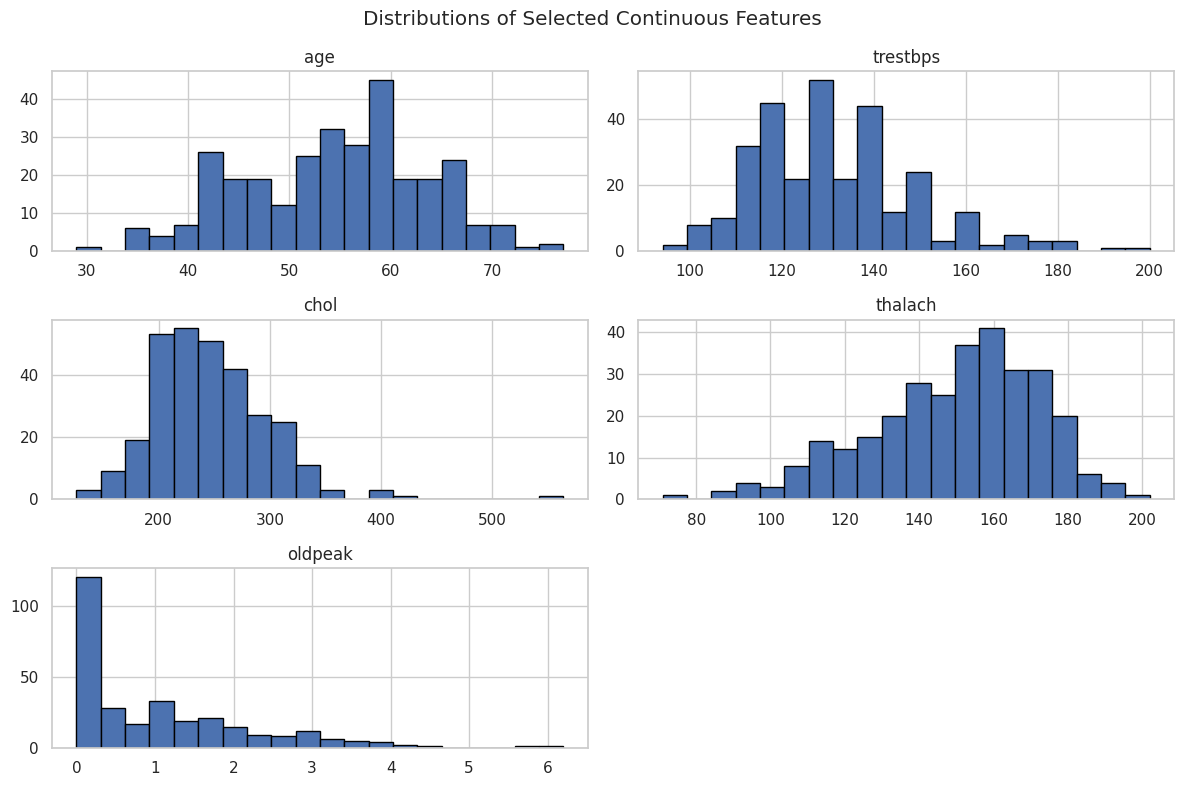

In [59]:
# Histograms for selected continuous variables
continuous_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
dataset[continuous_features].hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Distributions of Selected Continuous Features")
plt.tight_layout()
plt.show()

## 8. Prepare features and perform a stratified train/test split

The test set is held back until final evaluation. It is not used for random-seed selection, preprocessing decisions or cross-validation.

In [60]:
X = dataset.drop(columns="target").copy()
y = dataset["target"].astype(int).copy()

# Remove columns that are entirely missing, if any
all_missing_columns = X.columns[X.isna().all()].tolist()
if all_missing_columns:
    print("Dropping entirely missing feature columns:", all_missing_columns)
    X = X.drop(columns=all_missing_columns)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\\nTraining target proportions:")
display(y_train.value_counts(normalize=True).sort_index().round(3).to_frame("proportion"))
print("\\nTest target proportions:")
display(y_test.value_counts(normalize=True).sort_index().round(3).to_frame("proportion"))

Training set: (242, 13)
Test set: (61, 13)
\nTraining target proportions:


,proportion
target,
0,0.541
1,0.459


\nTest target proportions:


,proportion
target,
0,0.541
1,0.459


## 9. Define machine-learning models and preprocessing pipelines

Imputation and scaling are placed inside each pipeline. During cross-validation, each fold learns its own imputation and scaling parameters using only that fold's training portion. Tree-based models do not need scaling; distance- and margin-based models do.

In [61]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

def make_pipeline(estimator, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", estimator))
    return Pipeline(steps)

models = {
    "Logistic Regression": make_pipeline(
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), scale=True
    ),
    "Gaussian Naive Bayes": make_pipeline(GaussianNB(), scale=True),
    "Linear SVM": make_pipeline(
        SVC(kernel="linear", probability=True, random_state=RANDOM_STATE), scale=True
    ),
    "KNN (k=7)": make_pipeline(
        KNeighborsClassifier(n_neighbors=7), scale=True
    ),
    "Decision Tree": make_pipeline(
        DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False
    ),
    "Random Forest": make_pipeline(
        RandomForestClassifier(
            n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
        ), scale=False
    ),
    "Neural Network (11 hidden units)": make_pipeline(
        MLPClassifier(
            hidden_layer_sizes=(11,), activation="relu", solver="adam",
            max_iter=1500, early_stopping=True, random_state=RANDOM_STATE
        ), scale=True
    )
}

# Add XGBoost when the optional package is installed.
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = make_pipeline(
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_estimators=300,
            learning_rate=0.05,
            max_depth=3,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        scale=False
    )
except ImportError:
    print("XGBoost is not installed. The other seven models will run.")
    print("To add XGBoost, run: %pip install xgboost")

print("Models:", list(models.keys()))

Models: ['Logistic Regression', 'Gaussian Naive Bayes', 'Linear SVM', 'KNN (k=7)', 'Decision Tree', 'Random Forest', 'Neural Network (11 hidden units)', 'XGBoost']


## 10. Compare models using 5-fold stratified cross-validation

Cross-validation is performed only on the training set. The mean ROC-AUC is used to order this comparison, while accuracy, precision, recall and F1 are also reported. These are development estimates, not final test results.

In [62]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc"
}

cv_rows = []
for name, pipeline in models.items():
    result = cross_validate(
        pipeline, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=1,
        error_score="raise"
    )
    cv_rows.append({
        "Model": name,
        "CV accuracy": result["test_accuracy"].mean(),
        "CV precision": result["test_precision"].mean(),
        "CV recall": result["test_recall"].mean(),
        "CV F1": result["test_f1"].mean(),
        "CV ROC-AUC": result["test_roc_auc"].mean(),
        "CV ROC-AUC std": result["test_roc_auc"].std()
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    "CV ROC-AUC", ascending=False
).reset_index(drop=True)
display(cv_results.round(3))

,Model,CV accuracy,CV precision,CV recall,CV F1,CV ROC-AUC,CV ROC-AUC std
0,Gaussian Naive Bayes,0.818,0.823,0.774,0.795,0.897,0.023
1,Logistic Regression,0.826,0.844,0.765,0.801,0.896,0.015
2,Linear SVM,0.806,0.807,0.765,0.781,0.892,0.018
3,Random Forest,0.810,0.815,0.765,0.785,0.882,0.034
4,KNN (k=7),0.810,0.810,0.765,0.785,0.879,0.029
5,XGBoost,0.773,0.761,0.739,0.749,0.853,0.024
6,Neural Network (11 hidden units),0.649,0.574,0.937,0.711,0.786,0.040
7,Decision Tree,0.698,0.671,0.684,0.674,0.697,0.022


## 11. Fit on the full training set and evaluate on the held-out test set

Each model is fitted on the training set. The test set is used here for final evaluation only. Sensitivity is the same as recall for the positive class. Specificity measures the proportion of actual negative cases correctly classified.

In [63]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

fitted_models = {}
test_predictions = {}
test_rows = {}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

    y_pred = pipeline.predict(X_test)
    test_predictions[name] = y_pred

    if hasattr(pipeline, "predict_proba"):
        y_score = pipeline.predict_proba(X_test)[:, 1]
    elif hasattr(pipeline, "decision_function"):
        y_score = pipeline.decision_function(X_test)
    else:
        y_score = None

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan

    test_rows[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Sensitivity / Recall": sensitivity,
        "Specificity": specificity,
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score) if y_score is not None else np.nan,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

test_results = pd.DataFrame.from_dict(test_rows, orient="index")
test_results.index.name = "Model"
test_results = test_results.reset_index().sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True)

display(test_results.round(3))

,Model,Accuracy,Precision,Sensitivity / Recall,Specificity,F1-score,ROC-AUC,TN,FP,FN,TP
0,Random Forest,0.918,0.871,0.964,0.879,0.915,0.958,29,4,1,27
1,XGBoost,0.852,0.771,0.964,0.758,0.857,0.956,25,8,1,27
2,Gaussian Naive Bayes,0.869,0.794,0.964,0.788,0.871,0.952,26,7,1,27
3,Logistic Regression,0.869,0.812,0.929,0.818,0.867,0.951,27,6,2,26
4,KNN (k=7),0.836,0.765,0.929,0.758,0.839,0.945,25,8,2,26
5,Linear SVM,0.852,0.806,0.893,0.818,0.847,0.943,27,6,3,25
6,Neural Network (11 hidden units),0.607,0.538,1.000,0.273,0.700,0.859,9,24,0,28
7,Decision Tree,0.738,0.676,0.821,0.667,0.742,0.744,22,11,5,23


## 12. Confusion matrices and classification reports

False negatives (FN) are positive cases missed by the model; false positives (FP) are negative cases incorrectly flagged. In a screening context both matter, and the acceptable trade-off must be determined with clinical expertise.

\n Logistic Regression
                precision    recall  f1-score   support

No disease (0)       0.93      0.82      0.87        33
   Disease (1)       0.81      0.93      0.87        28

      accuracy                           0.87        61
     macro avg       0.87      0.87      0.87        61
  weighted avg       0.88      0.87      0.87        61



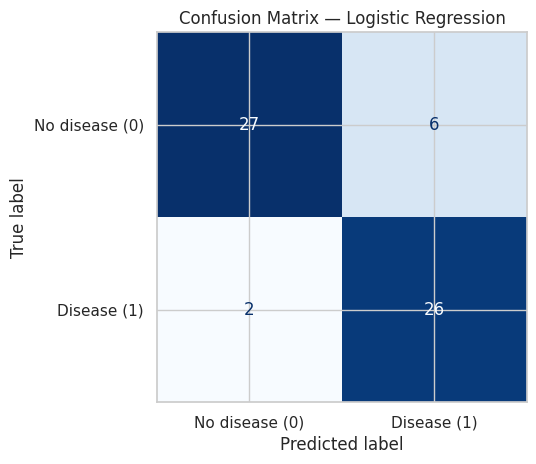

\n Gaussian Naive Bayes
                precision    recall  f1-score   support

No disease (0)       0.96      0.79      0.87        33
   Disease (1)       0.79      0.96      0.87        28

      accuracy                           0.87        61
     macro avg       0.88      0.88      0.87        61
  weighted avg       0.89      0.87      0.87        61



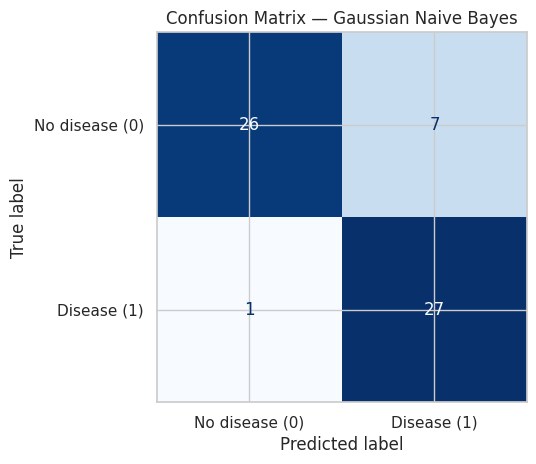

\n Linear SVM
                precision    recall  f1-score   support

No disease (0)       0.90      0.82      0.86        33
   Disease (1)       0.81      0.89      0.85        28

      accuracy                           0.85        61
     macro avg       0.85      0.86      0.85        61
  weighted avg       0.86      0.85      0.85        61



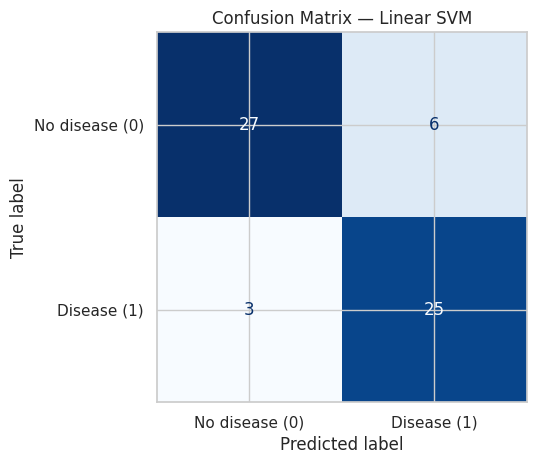

\n KNN (k=7)
                precision    recall  f1-score   support

No disease (0)       0.93      0.76      0.83        33
   Disease (1)       0.76      0.93      0.84        28

      accuracy                           0.84        61
     macro avg       0.85      0.84      0.84        61
  weighted avg       0.85      0.84      0.84        61



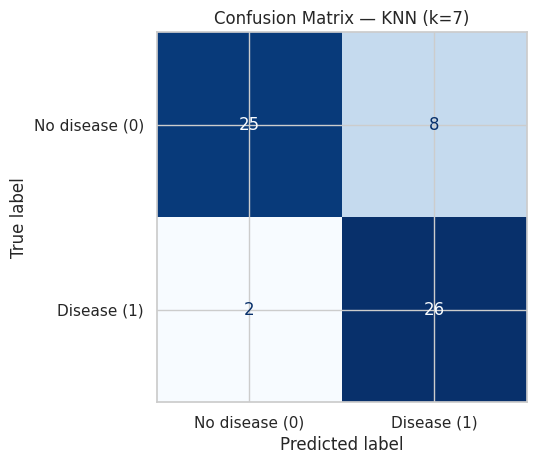

\n Decision Tree
                precision    recall  f1-score   support

No disease (0)       0.81      0.67      0.73        33
   Disease (1)       0.68      0.82      0.74        28

      accuracy                           0.74        61
     macro avg       0.75      0.74      0.74        61
  weighted avg       0.75      0.74      0.74        61



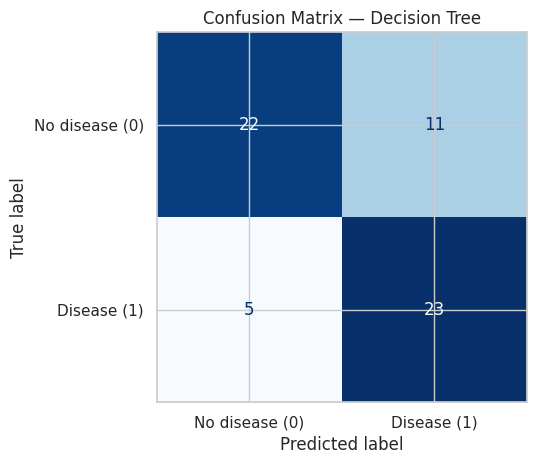

\n Random Forest
                precision    recall  f1-score   support

No disease (0)       0.97      0.88      0.92        33
   Disease (1)       0.87      0.96      0.92        28

      accuracy                           0.92        61
     macro avg       0.92      0.92      0.92        61
  weighted avg       0.92      0.92      0.92        61



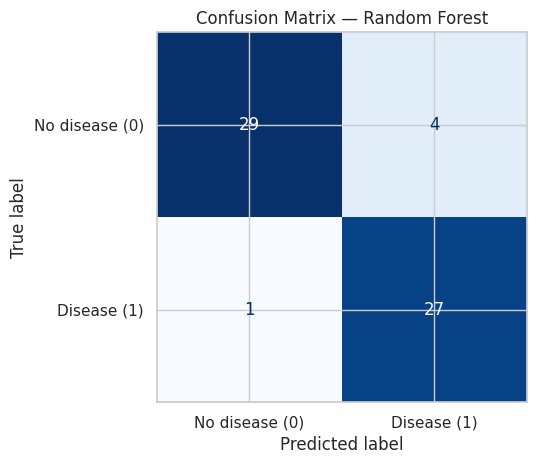

\n Neural Network (11 hidden units)
                precision    recall  f1-score   support

No disease (0)       1.00      0.27      0.43        33
   Disease (1)       0.54      1.00      0.70        28

      accuracy                           0.61        61
     macro avg       0.77      0.64      0.56        61
  weighted avg       0.79      0.61      0.55        61



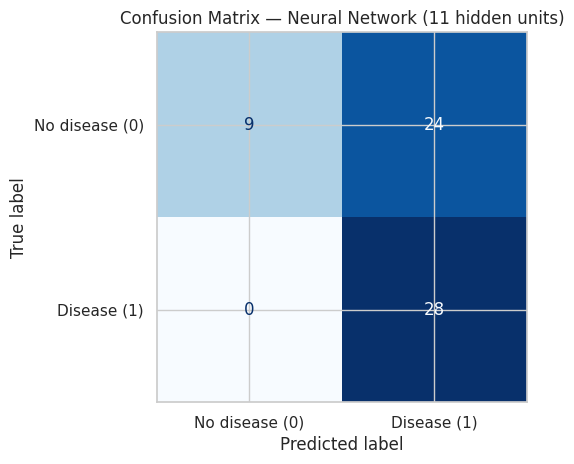

\n XGBoost
                precision    recall  f1-score   support

No disease (0)       0.96      0.76      0.85        33
   Disease (1)       0.77      0.96      0.86        28

      accuracy                           0.85        61
     macro avg       0.87      0.86      0.85        61
  weighted avg       0.87      0.85      0.85        61



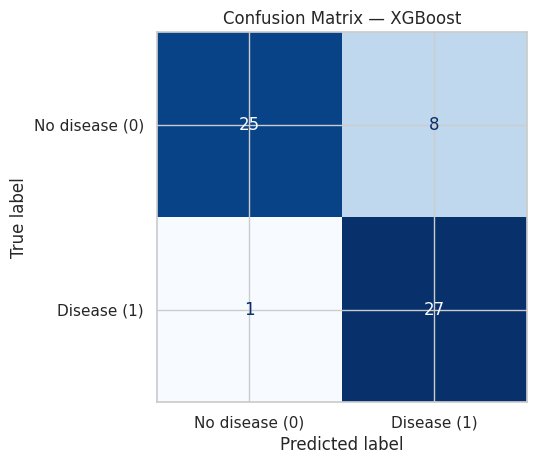

In [64]:
for name, y_pred in test_predictions.items():
    print("\\n", name)
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["No disease (0)", "Disease (1)"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        labels=[0, 1],
        display_labels=["No disease (0)", "Disease (1)"],
        cmap="Blues",
        colorbar=False
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

## 13. ROC curves

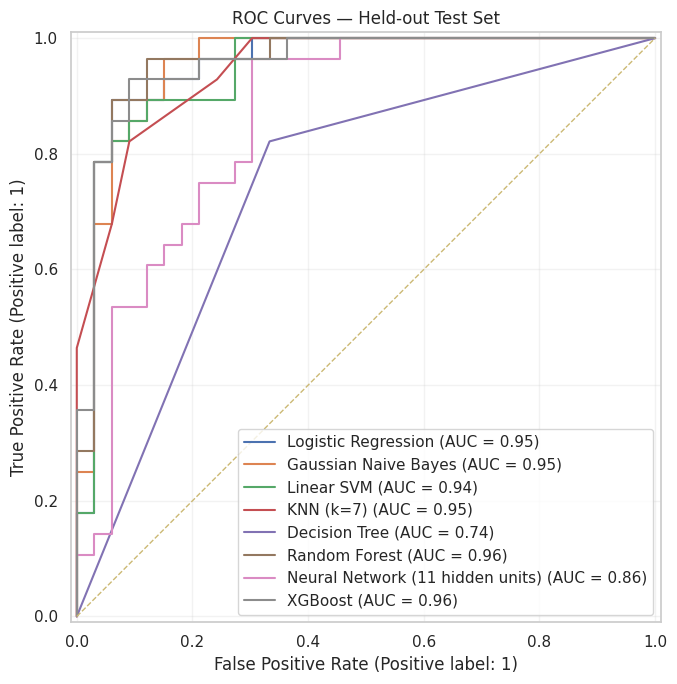

In [65]:
fig, ax = plt.subplots(figsize=(9, 7))
for name, pipeline in fitted_models.items():
    RocCurveDisplay.from_estimator(
        pipeline, X_test, y_test, name=name, ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Chance")
ax.set_title("ROC Curves — Held-out Test Set")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 14. Compare cross-validation and test metrics

,Model,CV accuracy,CV precision,CV recall,CV F1,CV ROC-AUC,CV ROC-AUC std,Accuracy,Precision,Sensitivity / Recall,Specificity,F1-score,ROC-AUC,TN,FP,FN,TP
0,Gaussian Naive Bayes,0.818,0.823,0.774,0.795,0.897,0.023,0.869,0.794,0.964,0.788,0.871,0.952,26,7,1,27
1,Logistic Regression,0.826,0.844,0.765,0.801,0.896,0.015,0.869,0.812,0.929,0.818,0.867,0.951,27,6,2,26
2,Linear SVM,0.806,0.807,0.765,0.781,0.892,0.018,0.852,0.806,0.893,0.818,0.847,0.943,27,6,3,25
3,Random Forest,0.810,0.815,0.765,0.785,0.882,0.034,0.918,0.871,0.964,0.879,0.915,0.958,29,4,1,27
4,KNN (k=7),0.810,0.810,0.765,0.785,0.879,0.029,0.836,0.765,0.929,0.758,0.839,0.945,25,8,2,26
5,XGBoost,0.773,0.761,0.739,0.749,0.853,0.024,0.852,0.771,0.964,0.758,0.857,0.956,25,8,1,27
6,Neural Network (11 hidden units),0.649,0.574,0.937,0.711,0.786,0.040,0.607,0.538,1.000,0.273,0.700,0.859,9,24,0,28
7,Decision Tree,0.698,0.671,0.684,0.674,0.697,0.022,0.738,0.676,0.821,0.667,0.742,0.744,22,11,5,23


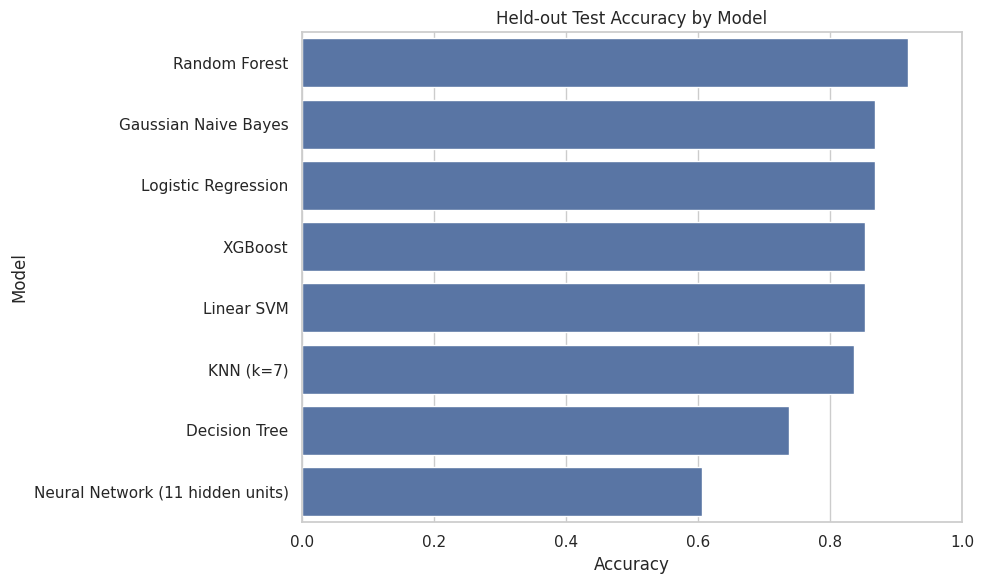

In [66]:
comparison = cv_results.merge(test_results, on="Model", how="left")
display(comparison.round(3))

plt.figure(figsize=(10, 6))
plot_data = test_results.sort_values("Accuracy", ascending=False)
sns.barplot(data=plot_data, x="Accuracy", y="Model")
plt.xlim(0, 1)
plt.title("Held-out Test Accuracy by Model")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

## 15. Mathematical foundations

### Logistic regression
For input vector \(x\), the model computes \(z = w^T x + b\) and maps it to a probability using the sigmoid function:

\[
\sigma(z)=\frac{1}{1+e^{-z}}
\]

The predicted class is 1 when the probability is at least the selected threshold (default 0.5). Binary cross-entropy is a common loss function:

\[
L=-\frac{1}{N}\sum_{i=1}^{N}\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]
\]

### K-nearest neighbours
KNN calculates distances between records. Euclidean distance is:

\[
d(x,y)=\sqrt{\sum_{j=1}^{p}(x_j-y_j)^2}
\]

The class is determined by the majority label among the \(k\) nearest training examples. Feature scaling is important because distance is scale-sensitive.

### Decision trees and random forests
A decision tree selects splits that reduce impurity. For binary classes, Gini impurity is:

\[
G=1-\sum_{k=1}^{2}p_k^2
\]

A random forest aggregates predictions from many trees, commonly using majority voting for classification.

## 16. Limitations, caveats and responsible use

1. **Small dataset:** the Cleveland dataset has only about 300 records. Estimates can vary substantially with the sample and split.
2. **Test-set leakage in the original notebook:** trying many random seeds and selecting the best Decision Tree or Random Forest result based on test accuracy indirectly uses test labels for model selection. This improved workflow removes that practice.
3. **Cross-validation is not external validation:** folds are drawn from the same dataset. Independent external data are needed to assess generalization.
4. **Feature scaling:** KNN and SVM are sensitive to feature scale. Standardization is performed inside pipelines to avoid leakage.
5. **Missing values and special codes:** missing values are median-imputed inside pipelines. Check UCI metadata for category codes and unknown-value conventions before interpreting them.
6. **Correlation is not causation:** correlation does not show that a variable causes heart disease and is not equivalent to model-specific feature importance.
7. **Accuracy alone is insufficient:** sensitivity, specificity, precision, F1 and ROC-AUC give complementary information. False negatives can be especially important in screening.
8. **Threshold and calibration:** this notebook uses the default classifier threshold. Real risk estimation requires calibration, confidence intervals, clinically justified thresholds and decision-utility analysis.
9. **Potential bias and generalizability:** the dataset is small and historically sourced; performance may not transfer to other populations, hospitals or modern clinical settings.
10. **Educational use only:** this notebook is not a medical device and must not be used to diagnose, rule out disease or guide treatment.

## 17. Reproducibility and package versions

In [67]:
import sklearn
print("Python packages:")
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

try:
    import xgboost
    print("XGBoost:", xgboost.__version__)
except ImportError:
    print("XGBoost: not installed (optional)")

Python packages:
pandas: 2.3.3
NumPy: 2.1.3
scikit-learn: 1.6.1
XGBoost: 3.4.1


### Run instructions

1. Run the installation cell if `ucimlrepo` is not installed.
2. Run all cells from top to bottom with an internet connection for the UCI dataset fetch.
3. If XGBoost is unavailable, the notebook will continue with the other seven models.
4. The final test metrics refer to one fixed stratified split (`random_state=42`); they are not guaranteed future performance.